# Konversi Citra ke Grayscale 8-bit

Notebook ini bertujuan untuk mengonversi seluruh dataset citra dari folder `Citra` (subfolder: `rapi` dan `berantakan`) menjadi format **grayscale 8-bit** menggunakan library **OpenCV** (`cv2`).

Hasil citra grayscale disimpan ke dalam folder `grayscale` dengan mempertahankan struktur subfolder:
- `grayscale/rapi/`
- `grayscale/berantakan/`

In [1]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. Konfigurasi direktori dataset (menggunakan foto-psd)
input_folder = 'foto-psd' if os.path.exists('foto-psd') else ('Citra' if os.path.exists('Citra') else 'citra')
output_folder = 'grayscale'

# Kategori subfolder yang akan diproses
categories = ['rapi', 'berantakan']

# Format file citra yang didukung
valid_extensions = ('.jpg', '.jpeg', '.png', '.bmp', '.webp')

def read_image(file_path):
    """Membaca citra dengan fallback buffer byte untuk keamanan path Windows."""
    img = cv2.imread(file_path)
    if img is None:
        img = cv2.imdecode(np.fromfile(file_path, dtype=np.uint8), cv2.IMREAD_COLOR)
    return img

def save_image(img, file_path):
    """Menyimpan citra dengan fallback handling path Windows."""
    os.makedirs(os.path.dirname(file_path), exist_ok=True)
    success = cv2.imwrite(file_path, img)
    if not success:
        ext = os.path.splitext(file_path)[1]
        _, buf = cv2.imencode(ext, img)
        buf.tofile(file_path)

In [2]:
# 2. Proses konversi citra ke Grayscale 8-bit
total_converted = 0
summary = {}

print(f"Memulai konversi citra dari '{input_folder}' ke '{output_folder}'...\n")

for category in categories:
    src_cat_dir = os.path.join(input_folder, category)
    dst_cat_dir = os.path.join(output_folder, category)
    
    # Buat direktori tujuan jika belum ada
    os.makedirs(dst_cat_dir, exist_ok=True)
    
    count = 0
    if os.path.exists(src_cat_dir):
        files = [f for f in os.listdir(src_cat_dir) if f.lower().endswith(valid_extensions)]
        print(f"[+] Memproses kategori '{category}' ({len(files)} citra)...")
        
        for file_name in files:
            src_path = os.path.join(src_cat_dir, file_name)
            dst_path = os.path.join(dst_cat_dir, file_name)
            
            # 1. Membaca citra warna (BGR)
            img_bgr = read_image(src_path)
            
            if img_bgr is not None:
                # 2. Mengonversi citra ke Grayscale 8-bit (1 channel, nilai pixel 0-255)
                img_gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
                
                # Memastikan tipe data citra adalah uint8 (8-bit)
                if img_gray.dtype != np.uint8:
                    img_gray = img_gray.astype(np.uint8)
                
                # 3. Menyimpan citra grayscale ke folder output
                save_image(img_gray, dst_path)
                count += 1
            else:
                print(f"    [Peringatan] Gagal membaca citra: {src_path}")
                
        summary[category] = count
        total_converted += count
        print(f"    -> Berhasil mengonversi dan menyimpan {count} citra ke '{dst_cat_dir}'\n")
    else:
        print(f"    [Error] Folder '{src_cat_dir}' tidak ditemukan!\n")

print("=" * 60)
print(f"Total seluruh citra yang berhasil dikonversi ke Grayscale: {total_converted}")
print("=" * 60)

Memulai konversi citra dari 'foto-psd' ke 'grayscale'...

[+] Memproses kategori 'rapi' (97 citra)...
    -> Berhasil mengonversi dan menyimpan 97 citra ke 'grayscale\rapi'

[+] Memproses kategori 'berantakan' (97 citra)...
    -> Berhasil mengonversi dan menyimpan 97 citra ke 'grayscale\berantakan'

Total seluruh citra yang berhasil dikonversi ke Grayscale: 194


Ringkasan Jumlah File pada Folder Grayscale:
- Kategori 'rapi': 97 file citra
- Kategori 'berantakan': 97 file citra

Informasi Sampel Citra: 24-003 Rapi 2.jpg
- Citra Asli (RGB)     : Dimensi (1792, 2400, 3), Tipe Data uint8
- Citra Grayscale (8-bit): Dimensi (1792, 2400), Tipe Data uint8 (8-bit single channel)


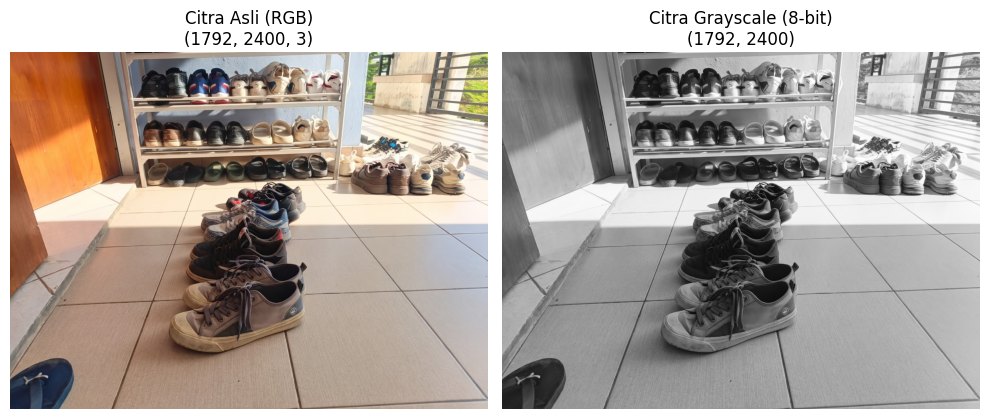

In [3]:
# 3. Verifikasi jumlah file tersimpan dan visualisasi perbandingan sampel
print("Ringkasan Jumlah File pada Folder Grayscale:")
for cat in categories:
    cat_path = os.path.join(output_folder, cat)
    if os.path.exists(cat_path):
        total_files = len([f for f in os.listdir(cat_path) if f.lower().endswith(valid_extensions)])
        print(f"- Kategori '{cat}': {total_files} file citra")

# Visualisasi sampel perbandingan Citra Asli (RGB) vs Citra Grayscale (8-bit)
sample_cat = 'rapi'
sample_cat_dir = os.path.join(output_folder, sample_cat)

if os.path.exists(sample_cat_dir):
    sample_files = [f for f in os.listdir(sample_cat_dir) if f.lower().endswith(valid_extensions)]
    if sample_files:
        sample_name = sample_files[0]
        orig_path = os.path.join(input_folder, sample_cat, sample_name)
        gray_path = os.path.join(output_folder, sample_cat, sample_name)
        
        # Baca citra asli dan citra grayscale
        img_orig_bgr = read_image(orig_path)
        img_orig_rgb = cv2.cvtColor(img_orig_bgr, cv2.COLOR_BGR2RGB)
        img_gray = cv2.imread(gray_path, cv2.IMREAD_GRAYSCALE)
        
        print(f"\nInformasi Sampel Citra: {sample_name}")
        print(f"- Citra Asli (RGB)     : Dimensi {img_orig_rgb.shape}, Tipe Data {img_orig_rgb.dtype}")
        print(f"- Citra Grayscale (8-bit): Dimensi {img_gray.shape}, Tipe Data {img_gray.dtype} (8-bit single channel)")
        
        fig, axes = plt.subplots(1, 2, figsize=(10, 5))
        axes[0].imshow(img_orig_rgb)
        axes[0].set_title(f"Citra Asli (RGB)\n{img_orig_rgb.shape}")
        axes[0].axis('off')
        
        axes[1].imshow(img_gray, cmap='gray')
        axes[1].set_title(f"Citra Grayscale (8-bit)\n{img_gray.shape}")
        axes[1].axis('off')
        
        plt.tight_layout()
        plt.show()